## Введение в нейронные сети
Нейронная сеть — это метод в искусственном интеллекте, который учит компьютеры обрабатывать данные таким же способом, как и человеческий мозг. Это тип процесса машинного обучения, называемый глубоким обучением, который использует взаимосвязанные узлы или нейроны в слоистой структуре, напоминающей человеческий мозг. Он создает адаптивную систему, с помощью которой компьютеры учатся на своих ошибках и постоянно совершенствуются. Таким образом, искусственные нейронные сети пытаются решать сложные задачи, такие как резюмирование документов или распознавание лиц, с более высокой точностью.

## Цель и задачи работы

**Цель:** Исследовать влияние различных гиперпараметров нейронной сети на точность распознавания рукописных цифр с использованием датасета MNIST.

**Задачи:**

1.  Проанализировать зависимость точности распознавания от количества скрытых слоев (от 1 до 5) при различных комбинациях алгоритмов оптимизации и функций потерь.
2.  Оценить влияние размера тестовой выборки (от 5% до 50% с шагом 5%) на точность распознавания.
3.  Изучить зависимость точности работы нейронной сети от количества эпох обучения.

## Пример работы нейрона сети

Вначале импортируем библиотеку numpy

In [ ]:
import numpy as np

Предположим, что нам известны вес и рост трех человек

In [ ]:
data = {
  'Иван': [84, 180, 1],
  'Мария': [57, 165, 0],
  'Анна': [62, 170, 0]
}

In [ ]:
# и даны следующие веса и смещение
w1, w2, b = 0.3, 0.1, -39

In [ ]:
# сделаем расчет для Ивана

# вначале умножим веса на данные и прибавим смещение
r = w1 * data['Иван'][0] + w2 * data['Иван'][1] + b

# пропустим результат через сигмоиду
np.round(1 / (1 + np.exp(-r)), 3)

0.985

Пройдемся по ключам и значениям нашего словаря с помощью метода .items()

In [ ]:
for k, v in data.items():
    # вначале умножим каждую строчку данных на веса и прибавим смещение
    r1 = w1 * v[0] + w2 * v[1] + b
    # затем применим сигмоиду
    r2 = 1 / (1 + np.exp(-r1))

    # если результат больше 0,5, модель предскажет мужской пол
    if r2 > 0.5:
      print(k, np.round(r2, 3), 'male')

    # в противном случае, женский
    else:
      print(k, np.round(r2, 3), 'female')

Иван 0.985 male
Мария 0.004 female
Анна 0.032 female


В итоге получен набор коэффициентов для каждого человека, по которому и определяется пол. Данный пример демонстрирует примерную работу сети с одним нейроном, с тем отличием, что:
 *   объемы исходных данных для реальной нейронной сети необходимы гораздо большие,
 *   нейронная сеть проходит множество этапов обучения, в ходе которых корреткируются веса и смещение для каждого нейрона,
 *   нейронные сети имеют несколько скрытых слоев и множество нейронов в каждом.



## Пример сети распознавания цифры с помощью библиотеки `Keras`

In [ ]:
# установим библиотеку tensorflow (через нее мы будем пользоваться keras) и модуль mnist
# !pip install tensorflow mnist

1. Подготовка данных

Импортируем библиотеку метод `fetch_openml` для подгрузки рукописных цифр (набор mnist)

In [ ]:
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split

# и библиотеку keras
from tensorflow import keras

Выполнил импорт датасета цифр и разделим его на тренировочную и тестовую части

In [ ]:
mnist = fetch_openml('mnist_784', as_frame=False, cache=False)

X = mnist.data.astype('float32')
y = mnist.target.astype('int64')

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

# посмотрим на размерность
print(X_train.shape)
print(y_train.shape)
print(y_train)
print(X_train)

/usr/local/lib/python3.10/dist-packages/sklearn/datasets/_openml.py:968: FutureWarning: The default value of `parser` will change from `'liac-arff'` to `'auto'` in 1.4. You can set `parser='auto'` to silence this warning. Therefore, an `ImportError` will be raised from 1.4 if the dataset is dense and pandas is not installed. Note that the pandas parser may return different data types. See the Notes Section in fetch_openml's API doc for details.
  warn(


(52500, 784)
(52500,)
[3 2 8 ... 1 0 0]
[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]


In [ ]:
# посмотрим в каком формате сохранились наши данные
type(X_train)

numpy.ndarray

In [ ]:
# сделаем то же самое с тестовыми данными
# X_test = mnist.test_images()
# y_test = mnist.test_labels()

# и также посмотрим на размерность
print(X_test.shape)
print(y_test.shape)

(17500, 784)
(17500,)


Для примера построим первые 5 изображений и их метки.

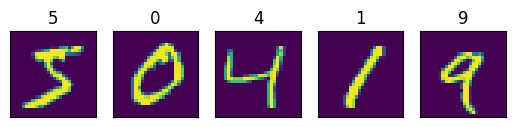

In [ ]:
import matplotlib.pyplot as plt

for i, (img, y) in enumerate(zip(X[:5].reshape(5, 28, 28), y[:5])):
    plt.subplot(151 + i)
    plt.imshow(img)
    plt.xticks([])
    plt.yticks([])
    plt.title(y)

In [ ]:
# функция np.min() возвращает минимальное значение,
# np.ptp() - разницу между максимальным и минимальным значениями (от англ. peak to peak)
X_train = 2. * (X_train - np.min(X_train)) / np.ptp(X_train) - 1
X_test = 2. * (X_test - np.min(X_test)) / np.ptp(X_test) - 1

In [ ]:
# снова воспользуемся функцией np.ptp()
np.ptp(X_train)

2.0

"вытянем" (flatten) изображения, с помощью метода reshape у нас будет 784 столбца (28 х 28), количество строк будет рассчитано автоматически (-1)

In [ ]:
X_train = X_train.reshape((-1, 784))
X_test = X_test.reshape((-1, 784))

# посмотрим на результат
print(X_train.shape)
print(X_test.shape)

(52500, 784)
(17500, 784)


Посмотрим на первое изображение [0], пиксели с 200 по 209

In [ ]:
X_train[0][200:210]

array([-1.       , -1.       , -1.       , -1.       , -1.       ,
       -1.       , -0.9529412, -1.       , -1.       , -1.       ],
      dtype=float32)

2. Конфигурация нейронной сети

In [ ]:
# импортируем класс Sequential
from tensorflow.keras.models import Sequential

# и создадим объект этого класса
model = Sequential()

In [ ]:
# импортируем класс Dense
from tensorflow.keras.layers import Dense

# и создадим первый скрытый слой (с указанием функции активации и размера входного слоя)
model.add(Dense(64, activation = 'sigmoid', input_shape = (784,)))

# затем второй скрытый слой
model.add(Dense(64, activation = 'sigmoid'))

# и наконец выходной слой
model.add(Dense(10, activation = 'softmax'))

3. Настройка нейросети

In [ ]:
# укажем настройки модели (см. страницу занятия)
model.compile(
  loss = 'categorical_crossentropy',
  optimizer = 'sgd',
  metrics = ['accuracy']
)

4. Обучение

In [ ]:
# вначале импортируем функцию to_categorical, чтобы сделать one-hot encoding

from tensorflow.keras.utils import to_categorical

In [ ]:
# обучаем модель методом .fit()
model.fit(
  X_train, # указываем обучающую выборку
  to_categorical(y_train), # делаем one-hot encoding целевой переменной
  epochs = 10 # по сути, эпоха показывает сколько раз алгоритм пройдется по всем данным
)

Epoch 1/10
1641/1641 [==============================] - 4s 2ms/step - loss: 2.0568 - accuracy: 0.4629
Epoch 2/10
1641/1641 [==============================] - 4s 2ms/step - loss: 1.3476 - accuracy: 0.7194
Epoch 3/10
1641/1641 [==============================] - 3s 2ms/step - loss: 0.8795 - accuracy: 0.7991
Epoch 4/10
1641/1641 [==============================] - 3s 2ms/step - loss: 0.6477 - accuracy: 0.8445
Epoch 5/10
1641/1641 [==============================] - 3s 2ms/step - loss: 0.5217 - accuracy: 0.8717
Epoch 6/10
1641/1641 [==============================] - 4s 2ms/step - loss: 0.4469 - accuracy: 0.8855
Epoch 7/10
1641/1641 [==============================] - 3s 2ms/step - loss: 0.3994 - accuracy: 0.8946
Epoch 8/10
1641/1641 [==============================] - 4s 2ms/step - loss: 0.3671 - accuracy: 0.9015
Epoch 9/10
1641/1641 [==============================] - 4s 3ms/step - loss: 0.3433 - accuracy: 0.9066
Epoch 10/10
1641/1641 [==============================] - 3s 2ms/step - loss: 0.324

5. Оценка качества модели

In [ ]:
# для оценки модели воспользуемся методом .evaluate()
model.evaluate(
  X_test, # который применим к тестовым данным
  to_categorical(y_test) # не забыв закодировать целевую переменную через one-hot encoding
)

547/547 [==============================] - 1s 1ms/step - loss: 0.3271 - accuracy: 0.9091


[0.32710662484169006, 0.9090856909751892]

6. Прогноз

In [ ]:
# передадим модели последние 10 изображений тестовой выборки
pred = model.predict(X_test[-10:])

# посмотрим на результат для первого изображения из десяти
pred[0]

1/1 [==============================] - 0s 85ms/step


array([4.8467646e-06, 9.4610095e-01, 1.2075580e-02, 6.5224455e-03,
       6.4088131e-04, 5.0758794e-03, 3.3721834e-04, 1.7508419e-03,
       2.6910152e-02, 5.8128126e-04], dtype=float32)

In [ ]:
# для кажого изображения (то есть строки, axis = 1)
# выведем индекс (максимальное значение), это и будет той цифрой, которую мы прогнозируем
print(np.argmax(pred, axis = 1))

# остается сравнить с целевой переменной
print(y_test[-10:])

[1 5 8 8 2 9 6 5 9 2]
[1 5 2 8 2 9 6 5 8 2]


7. Пример улучшения алгоритма

In [ ]:
# снова укажем настройки модели
model.compile(
  loss = 'categorical_crossentropy',
  optimizer = 'adam', # однако заменим алгоритм оптимизации
  metrics = ['accuracy']
)

# обучаем модель методом .fit()
model.fit(
  X_train, # указываем обучающую выборку
  to_categorical(y_train), # делаем one-hot encoding целевой переменной
  epochs = 10 # прописываем количество эпох
)

Epoch 1/10
1641/1641 [==============================] - 5s 2ms/step - loss: 0.2727 - accuracy: 0.9199
Epoch 2/10
1641/1641 [==============================] - 5s 3ms/step - loss: 0.1842 - accuracy: 0.9456
Epoch 3/10
1641/1641 [==============================] - 4s 2ms/step - loss: 0.1448 - accuracy: 0.9573
Epoch 4/10
1641/1641 [==============================] - 4s 3ms/step - loss: 0.1217 - accuracy: 0.9633
Epoch 5/10
1641/1641 [==============================] - 4s 2ms/step - loss: 0.1078 - accuracy: 0.9681
Epoch 6/10
1641/1641 [==============================] - 3s 2ms/step - loss: 0.0978 - accuracy: 0.9694
Epoch 7/10
1641/1641 [==============================] - 4s 2ms/step - loss: 0.0884 - accuracy: 0.9727
Epoch 8/10
1641/1641 [==============================] - 4s 3ms/step - loss: 0.0813 - accuracy: 0.9750
Epoch 9/10
1641/1641 [==============================] - 4s 2ms/step - loss: 0.0760 - accuracy: 0.9766
Epoch 10/10
1641/1641 [==============================] - 4s 2ms/step - loss: 0.070

In [ ]:
# и оцениваем результат "на тесте"
model.evaluate(
  X_test,
  to_categorical(y_test)
)

547/547 [==============================] - 1s 2ms/step - loss: 0.1190 - accuracy: 0.9641


[0.11896767467260361, 0.9640571475028992]